# Lecture Notes: Integration of Rational Functions by Partial Fractions
*Stewart, **Calculus**, §7.4*

**Learning objectives.** By the end of this lecture you should be able to:
1. Use long division to reduce an improper rational function to a polynomial plus a proper one.
2. Write the partial fraction decomposition for each type of factor in the denominator: distinct linear, repeated linear, irreducible quadratic and repeated irreducible quadratic.
3. Solve for the unknown coefficients and integrate each piece.
4. Use a rationalizing substitution to turn some non-rational integrands into rational ones.
5. Check every answer symbolically with **SymPy** and numerically with **NumPy**.

In [1]:
import numpy as np
import sympy as sp
import matplotlib.pyplot as plt
from IPython.display import Math, display

sp.init_printing()
x, u = sp.symbols("x u")
A, B, C, D, E = sp.symbols("A B C D E")

## 1. The idea: undo adding fractions

Adding fractions over a common denominator is routine:
$$\frac{2}{x - 1} - \frac{1}{x + 2} = \frac{2(x + 2) - (x - 1)}{(x - 1)(x + 2)} = \frac{x + 5}{x^2 + x - 2}.$$
Read backwards, this tells us how to integrate the right-hand side. Each piece on the left is easy:
$$\int\frac{x + 5}{x^2 + x - 2}\,dx = \int\Big(\frac{2}{x - 1} - \frac{1}{x + 2}\Big)dx = 2\ln|x - 1| - \ln|x + 2| + C.$$
The **method of partial fractions** is the systematic way to go from the right side back to the left.

SymPy does the decomposition with `apart` and the reverse with `together`. (SymPy writes $\log$ for $\ln$, and its `integrate` leaves out the absolute values.)

In [2]:
f = (x + 5) / (x**2 + x - 2)
pf = sp.apart(f)
display(Math(sp.latex(f) + " = " + sp.latex(pf)
             + r"\qquad\text{together: }" + sp.latex(sp.factor(sp.together(pf)))))
display(Math(r"\int " + sp.latex(f) + r"\,dx = " + sp.latex(sp.integrate(pf, x)) + " + C"))

<IPython.core.display.Math object>

<IPython.core.display.Math object>

### Proper and improper rational functions

A **rational function** is a ratio of polynomials $f(x) = P(x)/Q(x)$. It is **proper** if $\deg P < \deg Q$. Partial fractions only apply to proper functions. If $f$ is improper ($\deg P \ge \deg Q$), first divide:
$$\frac{P(x)}{Q(x)} = S(x) + \frac{R(x)}{Q(x)},\qquad \deg R < \deg Q.$$
The polynomial $S$ integrates directly, and $R/Q$ is proper.

### Example 1: $\displaystyle\int\frac{x^3 + x}{x - 1}\,dx$

The numerator has higher degree, so divide. Long division gives $x^3 + x = (x - 1)(x^2 + x + 2) + 2$, so
$$\int\frac{x^3 + x}{x - 1}\,dx = \int\Big(x^2 + x + 2 + \frac{2}{x - 1}\Big)dx = \frac{x^3}{3} + \frac{x^2}{2} + 2x + 2\ln|x - 1| + C.$$

### A checking function

As in the earlier sections, we check each antiderivative by differentiating it. If `simplify` can't reduce $F' - f$ to $0$, we compare numerically at points where the integrand is defined. With $\ln|\cdot|$ we write `log(abs(...))` and differentiate with $x$ real.

In [3]:
xr = sp.Symbol("x", real=True)

def check(F, integrand, var=x, pts=(0.3, 0.7, 1.9, 3.1, -0.4, -2.6)):
    # Verify F' = integrand: symbolically first, then numerically at sample points
    F, integrand = F.subs(var, xr), integrand.subs(var, xr)
    diff = sp.diff(F, xr) - integrand
    ok = sp.simplify(diff) == 0
    if not ok:
        vals = [diff.subs(xr, p).evalf() for p in pts]
        ok = all(abs(complex(v)) < 1e-10 for v in vals if v.is_finite)
    print("d/dx(answer) == integrand:", ok)
    return ok

In [4]:
S, R = sp.div(x**3 + x, x - 1)
display(Math(r"x^3 + x = (x - 1)\left(" + sp.latex(S) + r"\right) + " + sp.latex(R)))
F = x**3 / 3 + x**2 / 2 + 2 * x + 2 * sp.log(sp.Abs(x - 1))
display(Math(r"\int\frac{x^3 + x}{x - 1}\,dx = " + sp.latex(F) + " + C"))
check(F, (x**3 + x) / (x - 1));

<IPython.core.display.Math object>

<IPython.core.display.Math object>

d/dx(answer) == integrand: True


### The four cases

After dividing (if needed), factor the denominator $Q(x)$ as far as possible over the real numbers. Every real polynomial factors into **linear** factors $ax + b$ and **irreducible quadratic** factors $ax^2 + bx + c$ with $b^2 - 4ac < 0$. Each factor contributes terms to the decomposition:

| Case | Factor in $Q(x)$ | Terms in the decomposition |
|---|---|---|
| I | $a x + b$ (distinct) | $\dfrac{A}{ax + b}$ |
| II | $(a x + b)^r$ (repeated) | $\dfrac{A_1}{ax + b} + \dfrac{A_2}{(ax + b)^2} + \cdots + \dfrac{A_r}{(ax + b)^r}$ |
| III | $a x^2 + bx + c$ (distinct, irreducible) | $\dfrac{Ax + B}{ax^2 + bx + c}$ |
| IV | $(a x^2 + bx + c)^r$ (repeated, irreducible) | $\dfrac{A_1x + B_1}{ax^2 + bx + c} + \cdots + \dfrac{A_rx + B_r}{(ax^2 + bx + c)^r}$ |

The rule of thumb: the numerator over each factor has degree one less than the factor.

## 2. Case I: distinct linear factors

### Example 2: $\displaystyle\int\frac{x^2 + 2x - 1}{2x^3 + 3x^2 - 2x}\,dx$

The degree of the numerator is less than that of the denominator, so no division is needed. Factor:
$$2x^3 + 3x^2 - 2x = x(2x^2 + 3x - 2) = x(2x - 1)(x + 2).$$
Three distinct linear factors, so
$$\frac{x^2 + 2x - 1}{x(2x - 1)(x + 2)} = \frac{A}{x} + \frac{B}{2x - 1} + \frac{C}{x + 2}.$$
Multiply through by the denominator:
$$x^2 + 2x - 1 = A(2x - 1)(x + 2) + Bx(x + 2) + Cx(2x - 1).$$

**Method 1: compare coefficients.** Expand and collect powers of $x$:
$$x^2 + 2x - 1 = (2A + B + 2C)x^2 + (3A + 2B - C)x - 2A.$$
Matching coefficients gives the linear system
$$2A + B + 2C = 1,\qquad 3A + 2B - C = 2,\qquad -2A = -1,$$
whose solution is $A = \tfrac12$, $B = \tfrac15$, $C = -\tfrac1{10}$.

**Method 2: plug in the roots.** The identity holds for every $x$, so choose values that kill terms. $x = 0$ gives $-1 = -2A$; $x = \tfrac12$ gives $\tfrac14 = \tfrac54B$; $x = -2$ gives $-1 = 10C$. Same answer, much less work.

Integrate each piece (the middle one needs $u = 2x - 1$):
$$\int\frac{x^2 + 2x - 1}{2x^3 + 3x^2 - 2x}\,dx = \int\Big(\frac{1/2}{x} + \frac{1/5}{2x - 1} - \frac{1/10}{x + 2}\Big)dx = \frac12\ln|x| + \frac1{10}\ln|2x - 1| - \frac1{10}\ln|x + 2| + K.$$
(We use $K$ for the constant, since $C$ is taken.)

In [5]:
num, den = x**2 + 2 * x - 1, 2 * x**3 + 3 * x**2 - 2 * x
display(Math(sp.latex(den) + " = " + sp.latex(sp.factor(den))))

# Method 1: match coefficients of the identity
identity = sp.expand(A * (2 * x - 1) * (x + 2) + B * x * (x + 2) + C * x * (2 * x - 1) - num)
eqs = sp.Poly(identity, x).all_coeffs()
display(Math(r"\text{coefficients: }" + r",\quad ".join(sp.latex(e) + " = 0" for e in eqs)))
sol = sp.solve(eqs, [A, B, C])
display(Math(sp.latex(sol) + r"\qquad\text{apart: }" + sp.latex(sp.apart(num / den))))

F = sp.log(sp.Abs(x)) / 2 + sp.log(sp.Abs(2 * x - 1)) / 10 - sp.log(sp.Abs(x + 2)) / 10
display(Math(r"\int " + sp.latex(num / den) + r"\,dx = " + sp.latex(F) + " + K"))
check(F, num / den);

<IPython.core.display.Math object>

<IPython.core.display.Math object>

<IPython.core.display.Math object>

<IPython.core.display.Math object>

d/dx(answer) == integrand: True


A picture helps here. The integrand has vertical asymptotes at the three roots of the denominator, and near each one it behaves like the matching partial fraction. Each term "owns" one asymptote:

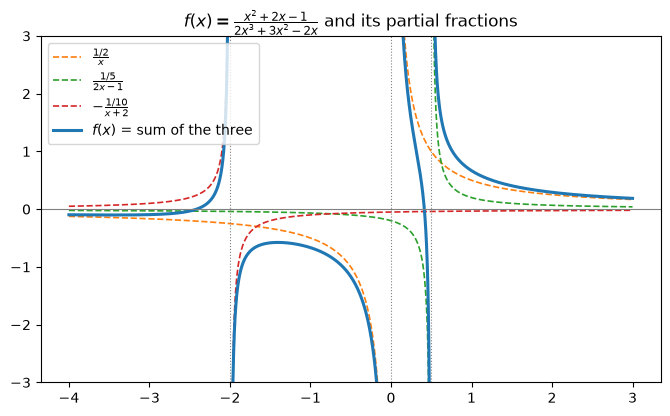

In [6]:
f_np = sp.lambdify(x, num / den, "numpy")
terms = [(sp.Rational(1, 2) / x, r"$\frac{1/2}{x}$"),
         (sp.Rational(1, 5) / (2 * x - 1), r"$\frac{1/5}{2x-1}$"),
         (-sp.Rational(1, 10) / (x + 2), r"$-\frac{1/10}{x+2}$")]
xs = np.linspace(-4, 3, 4001)
fig, ax = plt.subplots(figsize=(8, 4.5))
for i, (t, label) in enumerate(terms):
    ys = sp.lambdify(x, t, "numpy")(xs)
    ax.plot(xs, np.where(np.abs(ys) < 6, ys, np.nan), "--", color=f"C{i + 1}", lw=1.2, label=label)
ys = f_np(xs)
ax.plot(xs, np.where(np.abs(ys) < 6, ys, np.nan), "C0", lw=2.2, label=r"$f(x)$ = sum of the three")
for r in [0, 0.5, -2]:
    ax.axvline(r, color="gray", lw=0.8, ls=":")
ax.axhline(0, color="gray", lw=0.8)
ax.set_ylim(-3, 3)
ax.set_title(r"$f(x) = \frac{x^2+2x-1}{2x^3+3x^2-2x}$ and its partial fractions")
ax.legend(loc="upper left", fontsize=10)
plt.show()

### The cover-up shortcut

For a **distinct** linear factor $x - r$, the coefficient over it is found by covering up that factor in $P(x)/Q(x)$ and evaluating the rest at $x = r$. In Example 2, for $A$ over $x$: cover the $x$ and set $x = 0$ in $\dfrac{x^2 + 2x - 1}{(2x - 1)(x + 2)}$, giving $\dfrac{-1}{-2} = \dfrac12$. This is Method 2 in disguise. It doesn't work for repeated factors (except the highest power) or for quadratics.

In [7]:
factors = {A: x, B: 2 * x - 1, C: x + 2}
for coef, fac in factors.items():
    r = sp.solve(fac, x)[0]
    covered = sp.cancel(num / den * fac)          # remove that factor
    display(Math(rf"{sp.latex(coef)}:\ \text{{cover }} {sp.latex(fac)},\ x = {sp.latex(r)}:\quad "
                 + sp.latex(covered) + " = " + sp.latex(covered.subs(x, r))))

<IPython.core.display.Math object>

<IPython.core.display.Math object>

<IPython.core.display.Math object>

For $B$ the factor is $2x - 1$, not $x - \tfrac12$, and the shortcut still works as written: covering $2x - 1$ and setting $x = \tfrac12$ gives $\dfrac{1/4}{(1/2)(5/2)} = \dfrac15$.

### Example 3: $\displaystyle\int\frac{dx}{x^2 - a^2}$, where $a \ne 0$

Factor $x^2 - a^2 = (x - a)(x + a)$ and use the cover-up rule: over $x - a$ we get $\dfrac{1}{2a}$, over $x + a$ we get $\dfrac{1}{-2a}$. So
$$\int\frac{dx}{x^2 - a^2} = \frac1{2a}\int\Big(\frac1{x - a} - \frac1{x + a}\Big)dx = \frac1{2a}\ln\left|\frac{x - a}{x + a}\right| + C.$$
This is a formula worth remembering (it is in the integration table).

In [8]:
a = sp.Symbol("a", positive=True)
display(Math(r"\frac{1}{x^2-a^2} = " + sp.latex(sp.apart(1 / (x**2 - a**2), x))))
F = sp.log(sp.Abs((x - a) / (x + a))) / (2 * a)
display(Math(r"\int\frac{dx}{x^2-a^2} = " + sp.latex(F) + " + C"))
check(F.subs(a, 2), 1 / (x**2 - 4));

<IPython.core.display.Math object>

<IPython.core.display.Math object>

d/dx(answer) == integrand: True


## 3. Case II: repeated linear factors

If $(ax + b)^r$ divides $Q(x)$, then **every** power from $1$ to $r$ gets its own term. Forgetting the lower powers is the classic mistake: with only $\dfrac{B}{(x - 1)^2}$ there are not enough unknowns to match the numerator.

### Example 4: $\displaystyle\int\frac{x^4 - 2x^2 + 4x + 1}{x^3 - x^2 - x + 1}\,dx$

The function is improper, so divide first:
$$\frac{x^4 - 2x^2 + 4x + 1}{x^3 - x^2 - x + 1} = x + 1 + \frac{4x}{x^3 - x^2 - x + 1}.$$
Factor the denominator by grouping: $x^3 - x^2 - x + 1 = x^2(x - 1) - (x - 1) = (x - 1)^2(x + 1)$. The factor $x - 1$ appears twice, so
$$\frac{4x}{(x - 1)^2(x + 1)} = \frac{A}{x - 1} + \frac{B}{(x - 1)^2} + \frac{C}{x + 1}.$$
Multiplying out, $4x = A(x - 1)(x + 1) + B(x + 1) + C(x - 1)^2$. Plug in $x = 1$: $4 = 2B$, so $B = 2$. Plug in $x = -1$: $-4 = 4C$, so $C = -1$. Compare $x^2$ coefficients: $0 = A + C$, so $A = 1$. Therefore
$$\int\frac{x^4 - 2x^2 + 4x + 1}{x^3 - x^2 - x + 1}\,dx = \int\Big(x + 1 + \frac{1}{x - 1} + \frac{2}{(x - 1)^2} - \frac{1}{x + 1}\Big)dx = \frac{x^2}{2} + x + \ln\left|\frac{x - 1}{x + 1}\right| - \frac{2}{x - 1} + K.$$

In [9]:
num, den = x**4 - 2 * x**2 + 4 * x + 1, x**3 - x**2 - x + 1
S, R = sp.div(num, den)
display(Math(r"\text{quotient } " + sp.latex(S) + r",\quad \text{remainder } " + sp.latex(R)
             + r",\quad " + sp.latex(den) + " = " + sp.latex(sp.factor(den))))

identity = sp.expand(A * (x - 1) * (x + 1) + B * (x + 1) + C * (x - 1)**2 - R)
sol = sp.solve(sp.Poly(identity, x).all_coeffs(), [A, B, C])
display(Math(sp.latex(sol) + r"\qquad\text{apart: }" + sp.latex(sp.apart(num / den))))

F = x**2 / 2 + x + sp.log(sp.Abs((x - 1) / (x + 1))) - 2 / (x - 1)
display(Math(r"\int " + sp.latex(num / den) + r"\,dx = " + sp.latex(F) + " + K"))
check(F, num / den);

<IPython.core.display.Math object>

<IPython.core.display.Math object>

<IPython.core.display.Math object>

d/dx(answer) == integrand: True


## 4. Case III: distinct irreducible quadratic factors

An irreducible quadratic $ax^2 + bx + c$ (with $b^2 - 4ac < 0$) has no real roots, so it can't be split further. It gets a **linear** numerator $Ax + B$. To integrate such a term we need
$$\int\frac{dx}{x^2 + a^2} = \frac1a\tan^{-1}\Big(\frac xa\Big) + C,$$
together with the substitution $u = x^2 + a^2$ for the part with $x$ in the numerator.

### Example 5: $\displaystyle\int\frac{2x^2 - x + 4}{x^3 + 4x}\,dx$

Factor $x^3 + 4x = x(x^2 + 4)$. The quadratic $x^2 + 4$ is irreducible, so
$$\frac{2x^2 - x + 4}{x(x^2 + 4)} = \frac{A}{x} + \frac{Bx + C}{x^2 + 4}.$$
Multiplying out, $2x^2 - x + 4 = A(x^2 + 4) + (Bx + C)x = (A + B)x^2 + Cx + 4A$. Matching coefficients: $4A = 4$, $C = -1$, $A + B = 2$, so $A = 1$, $B = 1$, $C = -1$. Split the quadratic term in two:
$$\int\frac{2x^2 - x + 4}{x^3 + 4x}\,dx = \int\frac{dx}{x} + \int\frac{x\,dx}{x^2 + 4} - \int\frac{dx}{x^2 + 4} = \ln|x| + \frac12\ln(x^2 + 4) - \frac12\tan^{-1}\Big(\frac x2\Big) + K.$$
No absolute value is needed in $\ln(x^2 + 4)$, since $x^2 + 4 > 0$.

In [10]:
num, den = 2 * x**2 - x + 4, x**3 + 4 * x
identity = sp.expand(A * (x**2 + 4) + (B * x + C) * x - num)
sol = sp.solve(sp.Poly(identity, x).all_coeffs(), [A, B, C])
display(Math(sp.latex(sol) + r"\qquad\text{apart: }" + sp.latex(sp.apart(num / den))))

F = sp.log(sp.Abs(x)) + sp.log(x**2 + 4) / 2 - sp.atan(x / 2) / 2
display(Math(r"\int " + sp.latex(num / den) + r"\,dx = " + sp.latex(F) + " + K"))
check(F, num / den);

<IPython.core.display.Math object>

<IPython.core.display.Math object>

d/dx(answer) == integrand: True


### Example 6: $\displaystyle\int\frac{4x^2 - 3x + 2}{4x^2 - 4x + 3}\,dx$

The degrees are equal, so divide: $\dfrac{4x^2 - 3x + 2}{4x^2 - 4x + 3} = 1 + \dfrac{x - 1}{4x^2 - 4x + 3}$.

The quadratic is irreducible ($b^2 - 4ac = 16 - 48 < 0$), so the remainder is already a Case III term and there is nothing to decompose. Complete the square:
$$4x^2 - 4x + 3 = (2x - 1)^2 + 2.$$
Let $u = 2x - 1$, so $x = \tfrac12(u + 1)$ and $dx = \tfrac12du$. Then $x - 1 = \tfrac12(u - 1)$ and
$$\int\frac{x - 1}{4x^2 - 4x + 3}\,dx = \frac14\int\frac{u - 1}{u^2 + 2}\,du = \frac14\int\frac{u}{u^2 + 2}\,du - \frac14\int\frac{du}{u^2 + 2} = \frac18\ln(u^2 + 2) - \frac{1}{4\sqrt2}\tan^{-1}\Big(\frac{u}{\sqrt2}\Big) + C.$$
Putting it together:
$$\int\frac{4x^2 - 3x + 2}{4x^2 - 4x + 3}\,dx = x + \frac18\ln(4x^2 - 4x + 3) - \frac{1}{4\sqrt2}\tan^{-1}\Big(\frac{2x - 1}{\sqrt2}\Big) + C.$$

In [11]:
num, den = 4 * x**2 - 3 * x + 2, 4 * x**2 - 4 * x + 3
S, R = sp.div(num, den)
display(Math(sp.latex(num / den) + " = " + sp.latex(S) + " + " + sp.latex(R / den)
             + r",\qquad \text{discriminant} = " + sp.latex(sp.discriminant(den, x))))
display(Math(sp.latex(den) + " = " + sp.latex((2 * x - 1)**2 + 2) + r"\quad\text{: }"
             + str(sp.expand(den - ((2 * x - 1)**2 + 2)) == 0)))

F = x + sp.log(den) / 8 - sp.atan((2 * x - 1) / sp.sqrt(2)) / (4 * sp.sqrt(2))
display(Math(r"\int " + sp.latex(num / den) + r"\,dx = " + sp.latex(F) + " + C"))
check(F, num / den);

<IPython.core.display.Math object>

<IPython.core.display.Math object>

<IPython.core.display.Math object>

d/dx(answer) == integrand: True


## 5. Case IV: repeated irreducible quadratic factors

If $(ax^2 + bx + c)^r$ divides $Q(x)$, it contributes $r$ terms, each with a linear numerator. For example,
$$\frac{x^3 + x^2 + 1}{x(x - 1)(x^2 + x + 1)(x^2 + 1)^3} = \frac{A}{x} + \frac{B}{x - 1} + \frac{Cx + D}{x^2 + x + 1} + \frac{Ex + F}{x^2 + 1} + \frac{Gx + H}{(x^2 + 1)^2} + \frac{Ix + J}{(x^2 + 1)^3}.$$
That is ten unknowns, so in practice we let a computer solve for them. Count check: the number of unknowns always equals $\deg Q$ (here $1 + 1 + 2 + 6 = 10$).

### Example 7: $\displaystyle\int\frac{1 - x + 2x^2 - x^3}{x(x^2 + 1)^2}\,dx$

The form is
$$\frac{1 - x + 2x^2 - x^3}{x(x^2 + 1)^2} = \frac{A}{x} + \frac{Bx + C}{x^2 + 1} + \frac{Dx + E}{(x^2 + 1)^2}.$$
Multiplying by $x(x^2 + 1)^2$ and expanding:
$$-x^3 + 2x^2 - x + 1 = (A + B)x^4 + Cx^3 + (2A + B + D)x^2 + (C + E)x + A.$$
Matching coefficients: $A = 1$, $B = -1$, $C = -1$, $D = 1$, $E = 0$. So
$$\int\frac{1 - x + 2x^2 - x^3}{x(x^2 + 1)^2}\,dx = \int\Big(\frac1x - \frac{x}{x^2 + 1} - \frac{1}{x^2 + 1} + \frac{x}{(x^2 + 1)^2}\Big)dx = \ln|x| - \frac12\ln(x^2 + 1) - \tan^{-1}x - \frac{1}{2(x^2 + 1)} + K.$$
The last term uses $u = x^2 + 1$. (A term like $\dfrac{1}{(x^2 + 1)^2}$ would need the trig substitution $x = \tan\theta$ from §7.3.)

In [12]:
num, den = 1 - x + 2 * x**2 - x**3, x * (x**2 + 1)**2
identity = sp.expand(A * (x**2 + 1)**2 + (B * x + C) * x * (x**2 + 1) + (D * x + E) * x - num)
eqs = sp.Poly(identity, x).all_coeffs()
display(Math(r"\text{coefficients: }" + r",\quad ".join(sp.latex(e) + " = 0" for e in eqs)))
sol = sp.solve(eqs, [A, B, C, D, E])
display(Math(sp.latex(sol) + r"\qquad\text{apart: }" + sp.latex(sp.apart(num / den))))

F = sp.log(sp.Abs(x)) - sp.log(x**2 + 1) / 2 - sp.atan(x) - 1 / (2 * (x**2 + 1))
display(Math(r"\int " + sp.latex(num / den) + r"\,dx = " + sp.latex(F) + " + K"))
check(F, num / den);

<IPython.core.display.Math object>

<IPython.core.display.Math object>

<IPython.core.display.Math object>

d/dx(answer) == integrand: True


And a definite integral, compared against NumPy. On $[1, 2]$ the denominator is never zero:

In [13]:
val = sp.integrate(num / den, (x, 1, 2))
xs = np.linspace(1, 2, 100_001)
f_np = sp.lambdify(x, num / den, "numpy")
display(Math(r"\int_1^2 " + sp.latex(num / den) + r"\,dx = " + sp.latex(sp.simplify(F.subs(x, 2) - F.subs(x, 1)))
             + rf" \approx {float(val):.8f}"))
print(f"NumPy trapezoid: {np.trapezoid(f_np(xs), xs):.8f}")

<IPython.core.display.Math object>

NumPy trapezoid: 0.06325126


## 6. Rationalizing substitutions

Some integrands aren't rational but become rational after a substitution. If the integrand contains $\sqrt[n]{g(x)}$, try $u = \sqrt[n]{g(x)}$.

### Example 8: $\displaystyle\int\frac{\sqrt{x + 4}}{x}\,dx$

Let $u = \sqrt{x + 4}$. Then $u^2 = x + 4$, so $x = u^2 - 4$ and $dx = 2u\,du$:
$$\int\frac{\sqrt{x + 4}}{x}\,dx = \int\frac{u}{u^2 - 4}\,2u\,du = 2\int\frac{u^2}{u^2 - 4}\,du = 2\int\Big(1 + \frac{4}{u^2 - 4}\Big)du.$$
The last step is division. Using Example 3 with $a = 2$:
$$= 2u + 8\cdot\frac14\ln\left|\frac{u - 2}{u + 2}\right| + C = 2\sqrt{x + 4} + 2\ln\left|\frac{\sqrt{x + 4} - 2}{\sqrt{x + 4} + 2}\right| + C.$$

In [14]:
integrand_u = sp.sqrt(u**2) / (u**2 - 4) * 2 * u
integrand_u = sp.simplify(integrand_u.subs(sp.sqrt(u**2), u))
display(Math(r"\int\frac{\sqrt{x+4}}{x}\,dx = \int " + sp.latex(integrand_u) + r"\,du = \int\left("
             + sp.latex(sp.apart(integrand_u, u)) + r"\right)du"))

G = 2 * u + 2 * sp.log(sp.Abs((u - 2) / (u + 2)))
F = G.subs(u, sp.sqrt(x + 4))
display(Math(r"\int\frac{\sqrt{x+4}}{x}\,dx = " + sp.latex(F) + " + C"))
check(F, sp.sqrt(x + 4) / x, pts=(-3.5, -1.0, 0.5, 2.0, 7.0));

<IPython.core.display.Math object>

<IPython.core.display.Math object>

d/dx(answer) == integrand: True


## 7. Common mistakes

1. **Skipping the division.** Partial fractions need $\deg P < \deg Q$. If the numerator's degree is too high, the coefficients have no solution (or you get a wrong one).
2. **Not factoring completely.** $x^3 - x = x(x - 1)(x + 1)$, not $x(x^2 - 1)$. A quadratic is only Case III if its discriminant is negative.
3. **Missing powers for a repeated factor.** $(x - 1)^2$ needs both $\dfrac{A}{x - 1}$ and $\dfrac{B}{(x - 1)^2}$.
4. **A constant over a quadratic.** Over $x^2 + 4$ the numerator is $Bx + C$, not just $B$.
5. **Dropping the chain-rule factor.** $\displaystyle\int\frac{dx}{2x - 1} = \frac12\ln|2x - 1| + C$, not $\ln|2x - 1| + C$.
6. **Using partial fractions when a substitution is enough.** $\displaystyle\int\frac{x^2 + 1}{x^3 + 3x}\,dx$ is $\frac13\ln|x^3 + 3x| + C$ with $u = x^3 + 3x$.

Here are mistakes 1 and 3 checked: with too few unknowns, the system for the coefficients is inconsistent.

In [15]:
# Mistake 3: leave out A/(x-1) in Example 4's remainder 4x / ((x-1)^2 (x+1))
identity = sp.expand(B * (x + 1) + C * (x - 1)**2 - 4 * x)
display(Math(r"4x = B(x+1) + C(x-1)^2:\quad " + sp.latex(sp.solve(sp.Poly(identity, x).all_coeffs(), [B, C]))
             + r"\ \text{(no solution)}"))

# Mistake 1: try to decompose the improper (x^3 + x)/(x - 1) without dividing
identity = sp.expand(A - (x**3 + x))
display(Math(r"x^3 + x = A:\quad " + sp.latex(sp.solve(sp.Poly(identity, x).all_coeffs(), [A]))
             + r"\ \text{(no solution)}"))

# Mistake 6: the substitution route
F = sp.log(sp.Abs(x**3 + 3 * x)) / 3
display(Math(r"\int\frac{x^2+1}{x^3+3x}\,dx = " + sp.latex(F) + " + C"))
check(F, (x**2 + 1) / (x**3 + 3 * x));

<IPython.core.display.Math object>

<IPython.core.display.Math object>

<IPython.core.display.Math object>

d/dx(answer) == integrand: True


## 8. Practice problems

Try each by hand first, then compare with the answers below. Each answer is checked by differentiating it at points where the integrand is defined. If yours looks different, run `check` on it: it may differ only by a constant.

1. $\displaystyle\int\frac{5x + 1}{(2x + 1)(x - 1)}\,dx$
2. $\displaystyle\int\frac{x^2}{x + 1}\,dx$
3. $\displaystyle\int\frac{x^2 + 1}{(x - 3)(x - 2)^2}\,dx$
4. $\displaystyle\int\frac{10}{(x - 1)(x^2 + 9)}\,dx$
5. $\displaystyle\int\frac{x + 4}{x^2 + 2x + 5}\,dx$
6. $\displaystyle\int\frac{x^3 + 2x}{x^4 + 4x^2 + 3}\,dx$
7. $\displaystyle\int\frac{dx}{2\sqrt{x + 3} + x}$
8. $\displaystyle\int_0^1\frac{x - 4}{x^2 - 5x + 6}\,dx$

In [16]:
L = lambda e: sp.log(sp.Abs(e))
# (integrand, answer)
problems = [
    ((5 * x + 1) / ((2 * x + 1) * (x - 1)), L(2 * x + 1) / 2 + 2 * L(x - 1)),
    (x**2 / (x + 1), x**2 / 2 - x + L(x + 1)),
    ((x**2 + 1) / ((x - 3) * (x - 2)**2), 10 * L(x - 3) - 9 * L(x - 2) + 5 / (x - 2)),
    (10 / ((x - 1) * (x**2 + 9)), L(x - 1) - sp.log(x**2 + 9) / 2 - sp.atan(x / 3) / 3),
    ((x + 4) / (x**2 + 2 * x + 5), sp.log(x**2 + 2 * x + 5) / 2 + sp.Rational(3, 2) * sp.atan((x + 1) / 2)),
    ((x**3 + 2 * x) / (x**4 + 4 * x**2 + 3), sp.log(x**2 + 1) / 4 + sp.log(x**2 + 3) / 4),
    (1 / (2 * sp.sqrt(x + 3) + x), sp.Rational(3, 2) * L(sp.sqrt(x + 3) + 3) + L(sp.sqrt(x + 3) - 1) / 2),
]
for p, F in problems:
    display(Math(r"\int " + sp.latex(p) + r"\,dx = " + sp.latex(F) + " + C"))
    check(F, p, pts=(-2.6, -0.4, 0.3, 0.7, 3.4, 5.0))

p = (x - 4) / (x**2 - 5 * x + 6)
val = sp.integrate(p, (x, 0, 1))
xs = np.linspace(0, 1, 100_001)
display(Math(r"\int_0^1 " + sp.latex(p) + r"\,dx = " + sp.latex(sp.simplify(sp.expand_log(val, force=True)))
             + rf" \approx {float(val):.6f}"))
print(f"NumPy check: {np.trapezoid(sp.lambdify(x, p, 'numpy')(xs), xs):.6f}")

<IPython.core.display.Math object>

d/dx(answer) == integrand: True


<IPython.core.display.Math object>

d/dx(answer) == integrand: True


<IPython.core.display.Math object>

...

d/dx(answer) == integrand: True


<IPython.core.display.Math object>

d/dx(answer) == integrand: True


<IPython.core.display.Math object>

NumPy check: -0.980829


## Summary

**The steps** for $\displaystyle\int\frac{P(x)}{Q(x)}\,dx$:
1. Check for a simple $u$-substitution first.
2. If $\deg P \ge \deg Q$, divide: $P/Q = S + R/Q$.
3. Factor $Q$ completely into linear and irreducible quadratic factors.
4. Write the decomposition from the table, with one unknown per degree of $Q$.
5. Solve for the unknowns: plug in roots, then match coefficients for the rest.
6. Integrate each term.

| Factor | Term | Integral |
|---|---|---|
| $ax + b$ | $\dfrac{A}{ax + b}$ | $\dfrac{A}{a}\ln\lvert ax + b\rvert$ |
| $(ax + b)^k$, $k \ge 2$ | $\dfrac{A}{(ax + b)^k}$ | $\dfrac{-A}{a(k - 1)(ax + b)^{k - 1}}$ |
| $x^2 + a^2$ | $\dfrac{Bx + C}{x^2 + a^2}$ | $\dfrac{B}{2}\ln(x^2 + a^2) + \dfrac{C}{a}\tan^{-1}\dfrac{x}{a}$ |
| $ax^2 + bx + c$ | $\dfrac{Bx + C}{ax^2 + bx + c}$ | complete the square, then as above |
| $\sqrt[n]{g(x)}$ in the integrand | | try $u = \sqrt[n]{g(x)}$ |

$$\int\frac{dx}{x^2 - a^2} = \frac1{2a}\ln\left|\frac{x - a}{x + a}\right| + C,\qquad \int\frac{dx}{x^2 + a^2} = \frac1a\tan^{-1}\Big(\frac xa\Big) + C$$